# Record a Custom Isolated-Word Lip-Reading Dataset

This notebook records clips for **Hello, Hi, Yes, No, Good, Bad, Thanks,** and **Bye**. It is designed for repeated use by multiple people: choose a new anonymous `SPEAKER_ID` for each participant, then run the collection cell. Every accepted clip is stored twice: a `50 × 100` grayscale mouth-crop archive for training, and — when `SAVE_RAW_VIDEO` is enabled — an MP4 of the raw, unmodified webcam frames for the same three-second window.

> **Consent and privacy:** obtain each participant's consent before recording. When `SAVE_RAW_VIDEO` is enabled, full-frame webcam video of every accepted clip **is written to disk** (colour, native camera resolution, no audio), so the participant's consent must explicitly cover full-face video as well as mouth imagery. Set `SAVE_RAW_VIDEO = False` to record mouth-crop archives only; either way, no audio is ever saved. Mouth imagery and face video are biometric data, so protect the dataset and delete it when it is no longer required.

Each session targets 20 accepted recordings per word (160 clips per speaker). A three-second window begins after a countdown. During review, press **S** to save, **R** to retry, **P** to restart the replay, or **Q** to pause safely. Re-running the collection cell resumes incomplete work without overwriting accepted samples. Retried or rejected attempts save nothing — no raw video is kept for them.

## 1. Setup

Run this notebook locally in a GUI-capable Jupyter kernel with webcam permission. The existing MediaPipe face-landmarker model in this repository is used to locate the mouth.

In [1]:
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import os
import random
import re
import sys
import tempfile
import time
import uuid

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from IPython.display import Markdown, clear_output, display
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'processing' / 'face_landmarker.task').is_file():
            return candidate
    raise FileNotFoundError('Could not find processing/face_landmarker.task.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f'Project root: {PROJECT_ROOT}')
print(f'OpenCV: {cv2.__version__}; MediaPipe: {mp.__version__}')

Project root: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak
OpenCV: 4.11.0; MediaPipe: 0.10.35


## 2. Collection configuration

Change `SPEAKER_ID` before recording a different person. Use an anonymous identifier containing only letters, digits, `_`, or `-`; do not enter a participant's name.

`SAVE_RAW_VIDEO` controls whether the raw, full-frame webcam video of each accepted clip is also written to `data/custom_words/raw/<speaker>/<label>/<sample_id>.mp4`. With the default `mp4v` codec expect roughly 0.5–2 MB per three-second clip (about 100–300 MB per 160-clip speaker). `RAW_VIDEO_FOURCC` selects the encoder: `mp4v` works with every stock OpenCV build, while `avc1` (H.264) produces smaller files but is often unavailable — the recorder stops with a clear message if the chosen codec cannot be opened, and nothing is saved for that attempt.

The raw videos are excluded from git by this repository's `.gitignore` (`data/custom_words/raw/`); the mouth-crop archives and manifest are currently tracked, so commit those deliberately.

In [2]:
WORDS = ('hello', 'hi', 'yes', 'no', 'good', 'bad', 'thanks', 'bye')
SPEAKER_ID = 'speaker_test_samples1'  # Change this for every participant.
CAMERA_INDEX = 0
NUM_ROUNDS = 20
COUNTDOWN_SECONDS = 2.0
RECORD_SECONDS = 3.0
FRAME_WIDTH = 100
FRAME_HEIGHT = 50
MIN_FRAMES = 30
MIN_DETECTION_RATE = 0.75
SAVE_RAW_VIDEO = True  # Also save the raw, full-frame webcam video of accepted clips as MP4.
RAW_VIDEO_FOURCC = 'mp4v'  # Encoder fourcc; 'mp4v' works with every stock OpenCV build.
COLLECTION_SEED = 2026
OUTPUT_ROOT = PROJECT_ROOT / 'data' / 'custom_words'
MANIFEST_PATH = OUTPUT_ROOT / 'manifest.csv'
LANDMARKER_PATH = PROJECT_ROOT / 'processing' / 'face_landmarker.task'
RAW_VIDEO_ROOT = OUTPUT_ROOT / 'raw'

MANIFEST_COLUMNS = [
    'sample_id', 'speaker_id', 'label', 'repetition', 'relative_path', 'raw_video_path',
    'frame_count', 'fps', 'duration_seconds', 'detection_rate', 'captured_at',
]
SPEAKER_PATTERN = re.compile(r'^[A-Za-z0-9_-]+$')


def validate_configuration() -> None:
    if not SPEAKER_PATTERN.fullmatch(SPEAKER_ID):
        raise ValueError('SPEAKER_ID may contain only letters, digits, _ and -.')
    if SPEAKER_ID.lower() in {'name', 'firstname', 'lastname', 'your_name'}:
        raise ValueError('Use an anonymous speaker identifier, not a name.')
    if len(set(WORDS)) != len(WORDS) or not WORDS:
        raise ValueError('WORDS must contain unique labels.')
    if NUM_ROUNDS <= 0 or RECORD_SECONDS <= 0 or COUNTDOWN_SECONDS < 0:
        raise ValueError('Round and timing settings must be positive.')
    if not isinstance(SAVE_RAW_VIDEO, bool):
        raise ValueError('SAVE_RAW_VIDEO must be True or False.')
    if len(RAW_VIDEO_FOURCC) != 4:
        raise ValueError('RAW_VIDEO_FOURCC must be exactly four characters, e.g. "mp4v".')
    if not LANDMARKER_PATH.is_file():
        raise FileNotFoundError(f'Face landmarker not found: {LANDMARKER_PATH}')


validate_configuration()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f'Speaker: {SPEAKER_ID}')
print(f'Target: {NUM_ROUNDS} recordings × {len(WORDS)} words = {NUM_ROUNDS * len(WORDS)} clips')
print(f'Output: {OUTPUT_ROOT}')
if SAVE_RAW_VIDEO:
    print(f'Raw video: enabled ({RAW_VIDEO_FOURCC} MP4 under {RAW_VIDEO_ROOT.relative_to(PROJECT_ROOT)})')
else:
    print('Raw video: disabled (mouth-crop archives only)')

Speaker: speaker_test_samples1
Target: 20 recordings × 8 words = 160 clips
Output: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\data\custom_words
Raw video: enabled (mp4v MP4 under data\custom_words\raw)


## 3. Storage, mouth detection, and recording helpers

The following cell defines the collection workflow. It does not open the camera yet. Manifest, archive, and raw-video writes use temporary files followed by atomic replacement. Raw frames are buffered in memory for the current attempt only and are written to disk solely when the clip is accepted, so retried or rejected attempts leave no files behind.

In [3]:
LIP_LANDMARK_IDS = (
    61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291,
    78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308,
)


def empty_manifest() -> pd.DataFrame:
    return pd.DataFrame(columns=MANIFEST_COLUMNS)


def load_manifest() -> pd.DataFrame:
    if not MANIFEST_PATH.is_file():
        return empty_manifest()
    manifest = pd.read_csv(
        MANIFEST_PATH,
        dtype={
            'sample_id': 'string', 'speaker_id': 'string', 'label': 'string',
            'relative_path': 'string', 'raw_video_path': 'string', 'captured_at': 'string',
        },
    )
    if 'raw_video_path' not in manifest.columns:  # Manifests written before raw-video saving.
        manifest['raw_video_path'] = ''
    missing = set(MANIFEST_COLUMNS).difference(manifest.columns)
    if missing:
        raise ValueError(f'Manifest is missing columns: {sorted(missing)}')
    manifest['raw_video_path'] = manifest['raw_video_path'].fillna('')
    return manifest[MANIFEST_COLUMNS].copy()


def write_manifest_atomic(manifest: pd.DataFrame) -> None:
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    temporary_path = MANIFEST_PATH.with_suffix('.csv.tmp')
    manifest.to_csv(temporary_path, index=False)
    os.replace(temporary_path, MANIFEST_PATH)


def completed_keys(manifest: pd.DataFrame, speaker_id: str) -> set[tuple[str, int]]:
    if manifest.empty:
        return set()
    rows = manifest[manifest['speaker_id'].astype(str) == speaker_id]
    return {
        (str(row.label), int(row.repetition))
        for row in rows.itertuples(index=False)
        if str(row.label) in WORDS and 1 <= int(row.repetition) <= NUM_ROUNDS
    }


def write_raw_video(frames: list[np.ndarray], destination: Path, fps: float) -> None:
    if fps <= 0:
        raise ValueError('Raw video fps must be positive.')
    if len(frames) == 0:
        raise ValueError('Cannot write a raw video from zero frames.')
    height, width = frames[0].shape[:2]
    if frames[0].ndim != 3 or frames[0].shape[2] != 3:
        raise ValueError('Raw frames must be three-channel BGR images.')
    if any(frame.shape != frames[0].shape for frame in frames):
        raise ValueError('All raw frames must share the same shape.')

    destination.parent.mkdir(parents=True, exist_ok=True)
    # The temporary name must end in .mp4 so OpenCV picks an MP4 container.
    temporary_path = destination.with_name(f'{destination.stem}_{uuid.uuid4().hex[:8]}.tmp.mp4')
    writer = cv2.VideoWriter(
        str(temporary_path), cv2.VideoWriter_fourcc(*RAW_VIDEO_FOURCC), fps, (width, height)
    )
    if not writer.isOpened():
        writer.release()
        temporary_path.unlink(missing_ok=True)
        raise RuntimeError(
            f'OpenCV could not open a {RAW_VIDEO_FOURCC} MP4 writer ({temporary_path.name}). '
            "Try RAW_VIDEO_FOURCC = 'avc1' if your OpenCV build supports H.264, "
            'or set SAVE_RAW_VIDEO = False to record mouth-crop archives only.'
        )
    try:
        for frame in frames:
            writer.write(frame)
    except BaseException:
        writer.release()
        temporary_path.unlink(missing_ok=True)
        raise
    writer.release()
    os.replace(temporary_path, destination)


def save_accepted_clip(
    frames: np.ndarray,
    label: str,
    repetition: int,
    fps: float,
    detection_rate: float,
    raw_frames: list[np.ndarray] | None = None,
) -> Path:
    frames = np.asarray(frames)
    if frames.dtype != np.uint8 or frames.ndim != 3:
        raise ValueError('Saved frames must be uint8 with shape (time, height, width).')
    if frames.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
        raise ValueError(f'Unexpected mouth-frame shape: {frames.shape}')

    manifest = load_manifest()
    key_exists = (
        (manifest['speaker_id'].astype(str) == SPEAKER_ID)
        & (manifest['label'].astype(str) == label)
        & (pd.to_numeric(manifest['repetition'], errors='coerce') == repetition)
    ).any() if not manifest.empty else False
    if key_exists:
        raise FileExistsError(f'Already recorded: {SPEAKER_ID}/{label}/{repetition}')

    sample_id = f'{SPEAKER_ID}_{label}_r{repetition:02d}_{uuid.uuid4().hex[:10]}'
    clip_dir = OUTPUT_ROOT / 'clips' / SPEAKER_ID / label
    clip_dir.mkdir(parents=True, exist_ok=True)
    clip_path = clip_dir / f'{sample_id}.npz'
    if clip_path.exists():
        raise FileExistsError(f'Refusing to overwrite existing clip: {clip_path}')

    raw_path: Path | None = None
    if SAVE_RAW_VIDEO:
        if not raw_frames:
            raise ValueError('SAVE_RAW_VIDEO is enabled but no raw frames were captured.')
        raw_path = RAW_VIDEO_ROOT / SPEAKER_ID / label / f'{sample_id}.mp4'
        if raw_path.exists():
            raise FileExistsError(f'Refusing to overwrite existing raw video: {raw_path}')
        # Written before the archive and manifest so a codec failure aborts the save cleanly.
        write_raw_video(raw_frames, raw_path, fps)

    captured_at = datetime.now(timezone.utc).isoformat()
    with tempfile.NamedTemporaryFile(
        mode='wb', suffix='.npz.tmp', prefix=sample_id + '_', dir=clip_dir, delete=False
    ) as temporary_file:
        temporary_path = Path(temporary_file.name)
        np.savez_compressed(
            temporary_file,
            frames=frames,
            speaker_id=np.array(SPEAKER_ID),
            label=np.array(label),
            repetition=np.int32(repetition),
            fps=np.float32(fps),
            detection_rate=np.float32(detection_rate),
            captured_at=np.array(captured_at),
        )
    os.replace(temporary_path, clip_path)

    relative_path = clip_path.relative_to(OUTPUT_ROOT).as_posix()
    row = {
        'sample_id': sample_id,
        'speaker_id': SPEAKER_ID,
        'label': label,
        'repetition': repetition,
        'relative_path': relative_path,
        'raw_video_path': raw_path.relative_to(OUTPUT_ROOT).as_posix() if raw_path is not None else '',
        'frame_count': len(frames),
        'fps': float(fps),
        'duration_seconds': float(len(frames) / fps),
        'detection_rate': float(detection_rate),
        'captured_at': captured_at,
    }
    updated = pd.concat([manifest, pd.DataFrame([row])], ignore_index=True)
    write_manifest_atomic(updated)
    return clip_path


def create_landmarker():
    options = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=str(LANDMARKER_PATH)),
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
        min_face_detection_confidence=0.5,
        min_face_presence_confidence=0.5,
        min_tracking_confidence=0.5,
    )
    return vision.FaceLandmarker.create_from_options(options)


def next_timestamp_ms(state: dict) -> int:
    timestamp = int((time.perf_counter() - state['session_start']) * 1000)
    timestamp = max(timestamp, state['last_timestamp_ms'] + 1)
    state['last_timestamp_ms'] = timestamp
    return timestamp


def detect_mouth(
    frame: np.ndarray, landmarker, state: dict
) -> tuple[np.ndarray | None, tuple[int, int, int, int] | None, bool]:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = landmarker.detect_for_video(mp_image, next_timestamp_ms(state))
    fresh_detection = bool(result.face_landmarks)

    if fresh_detection:
        landmarks = result.face_landmarks[0]
        height, width = frame.shape[:2]
        points = np.asarray(
            [(int(landmarks[i].x * width), int(landmarks[i].y * height)) for i in LIP_LANDMARK_IDS],
            dtype=np.int32,
        )
        x_min, y_min = points.min(axis=0)
        x_max, y_max = points.max(axis=0)
        mouth_width = max(int(x_max - x_min), 1)
        mouth_height = max(int(y_max - y_min), 1)
        pad_x = max(int(mouth_width * 0.25), 12)
        pad_y = max(int(mouth_height * 0.60), 12)
        box = (
            max(int(x_min) - pad_x, 0),
            max(int(y_min) - pad_y, 0),
            min(int(x_max) + pad_x, width),
            min(int(y_max) + pad_y, height),
        )
        if box[2] > box[0] and box[3] > box[1]:
            state['last_box'] = box
        else:
            fresh_detection = False

    box = state.get('last_box')
    if box is None:
        return None, None, False
    x1, y1, x2, y2 = box
    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        return None, box, False
    crop = cv2.resize(crop, (FRAME_WIDTH, FRAME_HEIGHT), interpolation=cv2.INTER_AREA)
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    return crop.astype(np.uint8, copy=False), box, fresh_detection


def annotated_preview(
    frame: np.ndarray,
    box: tuple[int, int, int, int] | None,
    fresh_detection: bool,
    label: str,
    status: str,
    progress: str,
) -> np.ndarray:
    preview = frame.copy()
    if box is not None:
        colour = (0, 255, 0) if fresh_detection else (0, 165, 255)
        x1, y1, x2, y2 = box
        cv2.rectangle(preview, (x1, y1), (x2 - 1, y2 - 1), colour, 2)
    else:
        cv2.putText(preview, 'Mouth not detected', (20, 100), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    cv2.putText(preview, label.upper(), (20, 42), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 3, cv2.LINE_AA)
    cv2.putText(preview, status, (20, 76), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 255, 0), 2, cv2.LINE_AA)
    cv2.putText(preview, progress, (20, preview.shape[0] - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    return preview


def capture_attempt(
    camera, landmarker, state: dict, label: str, progress: str
) -> dict:
    state['last_box'] = None
    countdown_start = time.perf_counter()
    while time.perf_counter() - countdown_start < COUNTDOWN_SECONDS:
        success, frame = camera.read()
        if not success:
            return {'action': 'error', 'message': 'The camera stopped returning frames.'}
        crop, box, fresh = detect_mouth(frame, landmarker, state)
        remaining = max(0.0, COUNTDOWN_SECONDS - (time.perf_counter() - countdown_start))
        preview = annotated_preview(frame, box, fresh, label, f'Get ready: {remaining:.1f}s', progress)
        cv2.imshow('VisionSpeak dataset recorder', preview)
        if (cv2.waitKey(1) & 0xFF) in (ord('q'), ord('Q')):
            return {'action': 'pause'}

    frames: list[np.ndarray] = []
    raw_frames: list[np.ndarray] | None = [] if SAVE_RAW_VIDEO else None
    source_frame_count = 0
    fresh_detections = 0
    record_start = time.perf_counter()
    while time.perf_counter() - record_start < RECORD_SECONDS:
        success, frame = camera.read()
        if not success:
            return {'action': 'error', 'message': 'The camera stopped returning frames.'}
        source_frame_count += 1
        if raw_frames is not None:
            # camera.read() returns a fresh buffer each call and nothing mutates it,
            # so this is the unmodified frame: native resolution, no overlay.
            raw_frames.append(frame)
        crop, box, fresh = detect_mouth(frame, landmarker, state)
        fresh_detections += int(fresh)
        if crop is not None:
            frames.append(crop)
        elapsed = time.perf_counter() - record_start
        preview = annotated_preview(
            frame, box, fresh, label, f'RECORDING {elapsed:.1f}/{RECORD_SECONDS:.1f}s', progress
        )
        cv2.imshow('VisionSpeak dataset recorder', preview)
        if (cv2.waitKey(1) & 0xFF) in (ord('q'), ord('Q')):
            return {'action': 'pause'}

    elapsed = max(time.perf_counter() - record_start, 1e-6)
    fps = source_frame_count / elapsed
    detection_rate = fresh_detections / max(source_frame_count, 1)
    frame_array = np.asarray(frames, dtype=np.uint8)
    quality_reasons = []
    if len(frame_array) < MIN_FRAMES:
        quality_reasons.append(f'only {len(frame_array)} mouth frames (minimum {MIN_FRAMES})')
    if detection_rate < MIN_DETECTION_RATE:
        quality_reasons.append(f'detection rate {detection_rate:.0%} (minimum {MIN_DETECTION_RATE:.0%})')
    return {
        'action': 'review',
        'frames': frame_array,
        'raw_frames': raw_frames,
        'fps': fps,
        'detection_rate': detection_rate,
        'quality_reasons': quality_reasons,
    }


def review_clip(frames: np.ndarray, label: str, quality_reasons: list[str], fps: float) -> str:
    valid = not quality_reasons
    if len(frames) == 0:
        frames = np.zeros((1, FRAME_HEIGHT, FRAME_WIDTH), dtype=np.uint8)
    frame_index = 0
    delay_ms = max(1, int(1000 / max(min(fps, 60.0), 1.0)))
    while True:
        mouth = cv2.cvtColor(frames[frame_index], cv2.COLOR_GRAY2BGR)
        preview = cv2.resize(mouth, (FRAME_WIDTH * 5, FRAME_HEIGHT * 5), interpolation=cv2.INTER_NEAREST)
        colour = (0, 255, 0) if valid else (0, 0, 255)
        title = f'{label.upper()} - {frame_index + 1}/{len(frames)}'
        cv2.putText(preview, title, (12, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, colour, 2, cv2.LINE_AA)
        if valid:
            instruction = 'S save | R retry | P replay | Q pause'
        else:
            instruction = 'REJECTED: ' + '; '.join(quality_reasons)
            cv2.putText(preview, 'R retry | Q pause', (12, preview.shape[0] - 16), cv2.FONT_HERSHEY_SIMPLEX, 0.65, colour, 2, cv2.LINE_AA)
        cv2.putText(preview, instruction[:70], (12, 56), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colour, 1, cv2.LINE_AA)
        cv2.imshow('Review mouth-only clip', preview)
        key = cv2.waitKey(delay_ms) & 0xFF
        if key in (ord('s'), ord('S'), 10, 13) and valid:
            return 'save'
        if key in (ord('r'), ord('R')):
            return 'retry'
        if key in (ord('p'), ord('P')):
            frame_index = 0
            continue
        if key in (ord('q'), ord('Q')):
            return 'pause'
        frame_index = (frame_index + 1) % len(frames)


def collection_schedule(speaker_id: str) -> list[tuple[int, str]]:
    digest = hashlib.sha256(speaker_id.encode('utf-8')).digest()
    speaker_seed = int.from_bytes(digest[:8], 'big') ^ COLLECTION_SEED
    rng = random.Random(speaker_seed)
    schedule = []
    for repetition in range(1, NUM_ROUNDS + 1):
        round_words = list(WORDS)
        rng.shuffle(round_words)
        schedule.extend((repetition, word) for word in round_words)
    return schedule


def run_collection() -> None:
    validate_configuration()
    manifest = load_manifest()
    completed = completed_keys(manifest, SPEAKER_ID)
    schedule = collection_schedule(SPEAKER_ID)
    pending = [(rep, word) for rep, word in schedule if (word, rep) not in completed]
    total = NUM_ROUNDS * len(WORDS)
    if not pending:
        print(f'{SPEAKER_ID} already has all {total} requested clips.')
        return

    camera = cv2.VideoCapture(CAMERA_INDEX)
    if not camera.isOpened():
        camera.release()
        raise RuntimeError(f'Could not open camera index {CAMERA_INDEX}.')

    state = {'session_start': time.perf_counter(), 'last_timestamp_ms': -1, 'last_box': None}
    paused = False
    try:
        with create_landmarker() as landmarker:
            for repetition, label in pending:
                while True:
                    current = len(completed) + 1
                    progress = f'{SPEAKER_ID} | round {repetition}/{NUM_ROUNDS} | clip {current}/{total} | Q pauses'
                    result = capture_attempt(camera, landmarker, state, label, progress)
                    if result['action'] == 'pause':
                        paused = True
                        break
                    if result['action'] == 'error':
                        raise RuntimeError(result['message'])

                    decision = review_clip(
                        result['frames'], label, result['quality_reasons'], result['fps']
                    )
                    cv2.destroyWindow('Review mouth-only clip')
                    if decision == 'pause':
                        paused = True
                        break
                    if decision == 'retry':
                        continue

                    path = save_accepted_clip(
                        result['frames'], label, repetition, result['fps'], result['detection_rate'],
                        raw_frames=result.get('raw_frames'),
                    )
                    completed.add((label, repetition))
                    saved = f'Saved {len(completed)}/{total}: {path.relative_to(PROJECT_ROOT)}'
                    if SAVE_RAW_VIDEO:
                        raw_video = RAW_VIDEO_ROOT / SPEAKER_ID / label / f'{path.stem}.mp4'
                        saved += f' | raw video: {raw_video.relative_to(PROJECT_ROOT)}'
                    print(saved)
                    break
                if paused:
                    break
    finally:
        camera.release()
        cv2.destroyAllWindows()

    if paused:
        print(f'Paused safely with {len(completed)}/{total} clips. Run this cell again to resume.')
    else:
        print(f'Collection complete for {SPEAKER_ID}: {len(completed)}/{total} clips.')


print('Recording helpers are ready. No camera has been opened.')

Recording helpers are ready. No camera has been opened.


## 4. Record or resume this speaker

Confirm that the participant has consented — including to full-face video storage when `SAVE_RAW_VIDEO` is enabled — then run the next cell. Keep the face reasonably centred and evenly lit. Say the displayed word once during each **RECORDING** window. The green box means a fresh landmark detection; orange means the most recent valid box is being reused.

When `SAVE_RAW_VIDEO` is enabled, the raw, unmodified webcam frames of each accepted clip's RECORDING window are saved as an MP4 alongside the mouth-crop archive. The preview overlay (box, word, countdown) is never burned into the saved video.

The window must have keyboard focus for **S/R/P/Q** to work.

In [4]:
# This is the only cell that starts an interactive recording session.
run_collection()

Saved 1/160: data\custom_words\clips\speaker_test_samples1\bye\speaker_test_samples1_bye_r01_cc4d70f346.npz | raw video: data\custom_words\raw\speaker_test_samples1\bye\speaker_test_samples1_bye_r01_cc4d70f346.mp4
Saved 2/160: data\custom_words\clips\speaker_test_samples1\yes\speaker_test_samples1_yes_r01_3e8b80369a.npz | raw video: data\custom_words\raw\speaker_test_samples1\yes\speaker_test_samples1_yes_r01_3e8b80369a.mp4
Saved 3/160: data\custom_words\clips\speaker_test_samples1\good\speaker_test_samples1_good_r01_bc53906e78.npz | raw video: data\custom_words\raw\speaker_test_samples1\good\speaker_test_samples1_good_r01_bc53906e78.mp4
Saved 4/160: data\custom_words\clips\speaker_test_samples1\no\speaker_test_samples1_no_r01_abf032d27c.npz | raw video: data\custom_words\raw\speaker_test_samples1\no\speaker_test_samples1_no_r01_abf032d27c.mp4
Saved 5/160: data\custom_words\clips\speaker_test_samples1\thanks\speaker_test_samples1_thanks_r01_62c8d805c7.npz | raw video: data\custom_words

## 5. Audit the saved dataset

This audit checks manifest/archive agreement, duplicate recording slots, labels, array shape and type, embedded metadata, raw-video presence and readability, and missing recordings for the configured speaker. Clips recorded before raw-video saving was enabled (or with it disabled) are reported as an informational count, not as errors. Orphaned files — including unreferenced raw videos — are reported but never deleted automatically.

Clips without raw video (recorded before raw saving, or saving disabled): 640


### ✅ Dataset integrity checks passed

### Accepted clips by speaker and label

label,hello,hi,yes,no,good,bad,thanks,bye
speaker_id,,,,,,,,
TestID,20,20,20,20,20,20,20,20
speaker_002,20,20,20,20,20,20,20,20
speaker_004,20,20,20,20,20,20,20,20
speaker_007,20,20,20,20,20,20,20,20
speaker_test_samples,20,20,20,20,20,20,20,20
speaker_test_samples1,20,20,20,20,20,20,20,20


Missing clips for speaker_test_samples1: 0


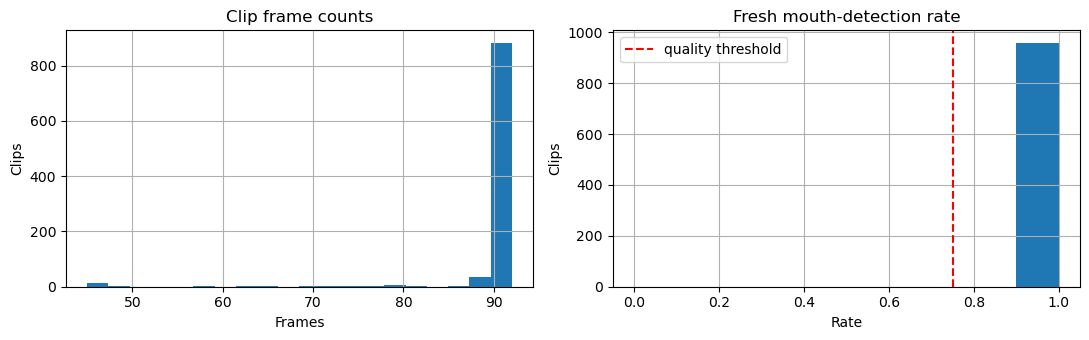

In [5]:
def audit_dataset() -> tuple[pd.DataFrame, pd.DataFrame]:
    manifest = load_manifest()
    issues: list[dict[str, str]] = []
    if manifest.empty:
        return manifest, pd.DataFrame([{'sample_id': '', 'issue': 'Manifest is empty.'}])

    duplicates = manifest.duplicated(['speaker_id', 'label', 'repetition'], keep=False)
    for row in manifest[duplicates].itertuples(index=False):
        issues.append({'sample_id': str(row.sample_id), 'issue': 'Duplicate speaker/label/repetition slot.'})

    referenced_paths: set[Path] = set()
    referenced_raw_paths: set[Path] = set()
    clips_without_raw_video = 0
    for row in manifest.itertuples(index=False):
        sample_id = str(row.sample_id)
        if str(row.label) not in WORDS:
            issues.append({'sample_id': sample_id, 'issue': f'Unknown label: {row.label}'})
        path = OUTPUT_ROOT / str(row.relative_path)
        referenced_paths.add(path.resolve())
        if not path.is_file():
            issues.append({'sample_id': sample_id, 'issue': f'Missing archive: {path}'})
            continue
        raw_relative = '' if pd.isna(row.raw_video_path) else str(row.raw_video_path)
        if raw_relative:
            raw_path = OUTPUT_ROOT / raw_relative
            referenced_raw_paths.add(raw_path.resolve())
            if not raw_path.is_file():
                issues.append({'sample_id': sample_id, 'issue': f'Missing raw video: {raw_path}'})
            elif raw_path.stat().st_size == 0:
                issues.append({'sample_id': sample_id, 'issue': f'Empty raw video: {raw_path}'})
            else:
                probe = cv2.VideoCapture(str(raw_path))
                try:
                    if not probe.isOpened() or probe.get(cv2.CAP_PROP_FRAME_COUNT) <= 0:
                        issues.append({'sample_id': sample_id, 'issue': f'Unreadable raw video: {raw_path}'})
                finally:
                    probe.release()
        else:
            clips_without_raw_video += 1
        try:
            with np.load(path, allow_pickle=False) as archive:
                if 'frames' not in archive.files:
                    raise ValueError('missing frames array')
                frames = archive['frames']
                if frames.dtype != np.uint8:
                    raise ValueError(f'frames dtype is {frames.dtype}, expected uint8')
                if frames.ndim != 3 or frames.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
                    raise ValueError(f'frames shape is {frames.shape}')
                if len(frames) != int(row.frame_count):
                    raise ValueError('frame count differs from manifest')
                if str(archive['label'].item()) != str(row.label):
                    raise ValueError('embedded label differs from manifest')
                if str(archive['speaker_id'].item()) != str(row.speaker_id):
                    raise ValueError('embedded speaker differs from manifest')
        except (OSError, ValueError, EOFError) as error:
            issues.append({'sample_id': sample_id, 'issue': str(error)})

    clips_root = OUTPUT_ROOT / 'clips'
    if clips_root.is_dir():
        for path in clips_root.rglob('*.npz'):
            if path.resolve() not in referenced_paths:
                issues.append({'sample_id': '', 'issue': f'Orphaned archive: {path}'})

    if RAW_VIDEO_ROOT.is_dir():
        for path in RAW_VIDEO_ROOT.rglob('*.mp4'):
            if path.resolve() not in referenced_raw_paths:
                issues.append({'sample_id': '', 'issue': f'Orphaned raw video: {path}'})

    if clips_without_raw_video:
        print(
            f'Clips without raw video (recorded before raw saving, or saving disabled): '
            f'{clips_without_raw_video}'
        )

    return manifest, pd.DataFrame(issues, columns=['sample_id', 'issue'])


manifest, audit_issues = audit_dataset()
if audit_issues.empty:
    display(Markdown('### ✅ Dataset integrity checks passed'))
else:
    display(Markdown(f'### ⚠️ {len(audit_issues)} dataset issue(s) found'))
    display(audit_issues)

if not manifest.empty:
    counts = manifest.pivot_table(index='speaker_id', columns='label', values='sample_id', aggfunc='count', fill_value=0)
    display(Markdown('### Accepted clips by speaker and label'))
    display(counts.reindex(columns=WORDS, fill_value=0))

    expected = pd.MultiIndex.from_product([[SPEAKER_ID], WORDS, range(1, NUM_ROUNDS + 1)], names=['speaker_id', 'label', 'repetition'])
    actual = pd.MultiIndex.from_frame(manifest[['speaker_id', 'label', 'repetition']].assign(repetition=lambda x: x.repetition.astype(int)))
    missing = expected.difference(actual)
    print(f'Missing clips for {SPEAKER_ID}: {len(missing)}')
    if len(missing):
        display(pd.DataFrame(missing.tolist(), columns=missing.names).head(30))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    manifest['frame_count'].astype(float).hist(ax=axes[0], bins=20)
    axes[0].set(title='Clip frame counts', xlabel='Frames', ylabel='Clips')
    manifest['detection_rate'].astype(float).hist(ax=axes[1], bins=np.linspace(0, 1, 11))
    axes[1].axvline(MIN_DETECTION_RATE, color='red', linestyle='--', label='quality threshold')
    axes[1].set(title='Fresh mouth-detection rate', xlabel='Rate', ylabel='Clips')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

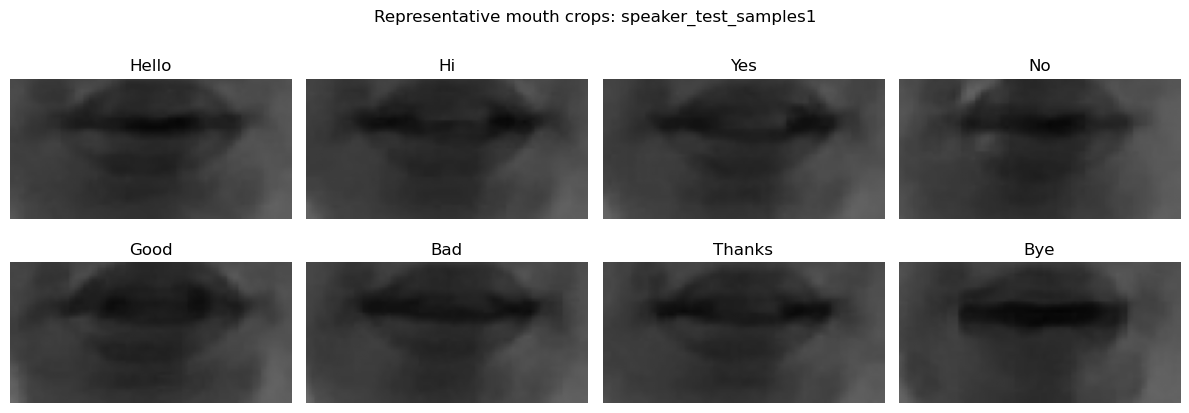

In [6]:
def show_contact_sheet(manifest: pd.DataFrame, speaker_id: str | None = None) -> None:
    rows = manifest.copy()
    if speaker_id is not None:
        rows = rows[rows['speaker_id'].astype(str) == speaker_id]
    if rows.empty:
        print('No clips are available for a contact sheet.')
        return
    rows = rows.sort_values(['label', 'repetition']).groupby('label', as_index=False).first()
    fig, axes = plt.subplots(2, 4, figsize=(12, 4.5))
    for axis, label in zip(axes.flat, WORDS):
        match = rows[rows['label'].astype(str) == label]
        if match.empty:
            axis.text(0.5, 0.5, 'missing', ha='center', va='center')
        else:
            row = match.iloc[0]
            with np.load(OUTPUT_ROOT / row['relative_path'], allow_pickle=False) as archive:
                frames = archive['frames']
                axis.imshow(frames[len(frames) // 2], cmap='gray', vmin=0, vmax=255)
        axis.set_title(label.title())
        axis.axis('off')
    plt.suptitle(f'Representative mouth crops: {speaker_id or "all speakers"}')
    plt.tight_layout()
    plt.show()


manifest = load_manifest()
show_contact_sheet(manifest, SPEAKER_ID)

## 6. Reproducible, on-demand augmentation

Augmentation does **not** create new articulations or new speakers. It only makes training less sensitive to small camera, timing, and lighting changes. Spatial parameters are held constant across a clip to avoid artificial frame-to-frame shaking. Original arrays are never changed.

Apply augmentation only after splitting by speaker, and only to training clips. Never augment validation or test clips.

In [7]:
def temporal_resample(frames: np.ndarray, output_length: int) -> np.ndarray:
    if output_length <= 0:
        raise ValueError('output_length must be positive.')
    if len(frames) == output_length:
        return frames.copy()
    positions = np.linspace(0, len(frames) - 1, output_length)
    left = np.floor(positions).astype(int)
    right = np.minimum(left + 1, len(frames) - 1)
    weights = (positions - left).astype(np.float32)[:, None, None]
    result = frames[left].astype(np.float32) * (1.0 - weights) + frames[right].astype(np.float32) * weights
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)


def augment_clip(frames: np.ndarray, seed: int) -> np.ndarray:
    source = np.asarray(frames)
    if source.dtype != np.uint8 or source.ndim != 3:
        raise ValueError('frames must be uint8 with shape (time, height, width).')
    if len(source) == 0 or source.shape[1:] != (FRAME_HEIGHT, FRAME_WIDTH):
        raise ValueError(f'Expected non-empty clips shaped (time, {FRAME_HEIGHT}, {FRAME_WIDTH}).')
    rng = np.random.default_rng(seed)

    speed = rng.uniform(0.85, 1.15)
    output_length = max(1, int(round(len(source) / speed)))
    augmented = temporal_resample(source, output_length)

    angle = rng.uniform(-4.0, 4.0)
    scale = rng.uniform(0.94, 1.06)
    translate_x = rng.uniform(-3.0, 3.0)
    translate_y = rng.uniform(-2.0, 2.0)
    matrix = cv2.getRotationMatrix2D((FRAME_WIDTH / 2, FRAME_HEIGHT / 2), angle, scale)
    matrix[:, 2] += (translate_x, translate_y)
    augmented = np.stack([
        cv2.warpAffine(frame, matrix, (FRAME_WIDTH, FRAME_HEIGHT), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        for frame in augmented
    ])

    if rng.random() < 0.5:
        augmented = augmented[:, :, ::-1].copy()
    contrast = rng.uniform(0.85, 1.15)
    brightness = rng.uniform(-12.0, 12.0)
    augmented = augmented.astype(np.float32) * contrast + brightness
    if rng.random() < 0.25:
        augmented = np.stack([cv2.GaussianBlur(frame, (3, 3), 0) for frame in augmented])
    noise_sigma = rng.uniform(0.0, 4.0)
    if noise_sigma > 0:
        augmented += rng.normal(0.0, noise_sigma, size=augmented.shape).astype(np.float32)
    return np.clip(np.rint(augmented), 0, 255).astype(np.uint8)


# Lightweight self-tests: determinism, input immutability, shape/type/range, and temporal variation.
synthetic = np.zeros((60, FRAME_HEIGHT, FRAME_WIDTH), dtype=np.uint8)
for index in range(len(synthetic)):
    cv2.circle(synthetic[index], (20 + index // 3, 25), 7, 180, -1)
original = synthetic.copy()
first = augment_clip(synthetic, seed=123)
second = augment_clip(synthetic, seed=123)
assert np.array_equal(synthetic, original), 'augment_clip mutated its input'
assert np.array_equal(first, second), 'same seed did not reproduce the same augmentation'
assert first.dtype == np.uint8 and first.shape[1:] == (FRAME_HEIGHT, FRAME_WIDTH)
assert 0 <= int(first.min()) <= int(first.max()) <= 255
assert any(len(augment_clip(synthetic, seed=i)) != len(synthetic) for i in range(20)), 'temporal augmentation did not vary length'
print('Augmentation self-tests passed.')

Augmentation self-tests passed.


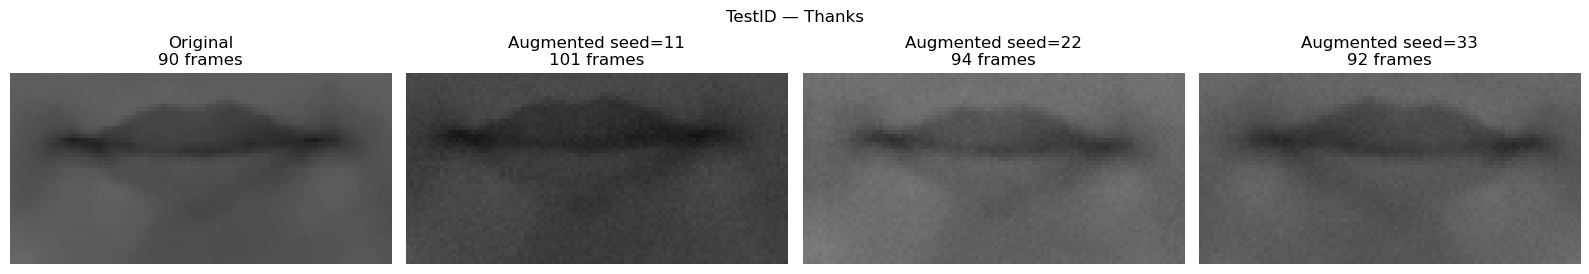

In [8]:
def preview_augmentations(manifest: pd.DataFrame, seeds=(11, 22, 33)) -> None:
    if manifest.empty:
        print('Record at least one clip before previewing augmentation.')
        return
    row = manifest.iloc[0]
    with np.load(OUTPUT_ROOT / row['relative_path'], allow_pickle=False) as archive:
        original = archive['frames'].copy()
    variants = [original] + [augment_clip(original, seed) for seed in seeds]
    titles = ['Original'] + [f'Augmented seed={seed}' for seed in seeds]
    fig, axes = plt.subplots(1, len(variants), figsize=(4 * len(variants), 3))
    for axis, variant, title in zip(np.atleast_1d(axes), variants, titles):
        axis.imshow(variant[len(variant) // 2], cmap='gray', vmin=0, vmax=255)
        axis.set_title(f'{title}\n{len(variant)} frames')
        axis.axis('off')
    plt.suptitle(f'{row["speaker_id"]} — {str(row["label"]).title()}')
    plt.tight_layout()
    plt.show()


manifest = load_manifest()
preview_augmentations(manifest)

## 7. Speaker-level train/validation/test splits

Choose entire speakers for validation and testing only after enough people have contributed. Leave both lists empty while collecting. The helper refuses unknown or overlapping speakers and never chooses holdout speakers automatically.

In [9]:
VALIDATION_SPEAKERS: list[str] = []  # Example later: ['speaker_004']
TEST_SPEAKERS: list[str] = []        # Example later: ['speaker_005']


def assign_speaker_splits(
    manifest: pd.DataFrame,
    validation_speakers: list[str],
    test_speakers: list[str],
) -> pd.DataFrame:
    validation = set(map(str, validation_speakers))
    test = set(map(str, test_speakers))
    overlap = validation.intersection(test)
    if overlap:
        raise ValueError(f'Speakers cannot be in both validation and test: {sorted(overlap)}')
    known = set(manifest['speaker_id'].astype(str)) if not manifest.empty else set()
    unknown = (validation | test).difference(known)
    if unknown:
        raise ValueError(f'Unknown holdout speakers: {sorted(unknown)}')

    result = manifest.copy()
    result['split'] = 'train'
    result.loc[result['speaker_id'].astype(str).isin(validation), 'split'] = 'validation'
    result.loc[result['speaker_id'].astype(str).isin(test), 'split'] = 'test'
    if not result.empty and not (result['split'] == 'train').any():
        raise ValueError('At least one speaker must remain in the training split.')
    return result


manifest = load_manifest()
split_manifest = assign_speaker_splits(manifest, VALIDATION_SPEAKERS, TEST_SPEAKERS)
if not split_manifest.empty:
    display(split_manifest.groupby(['split', 'speaker_id']).size().rename('clips').to_frame())
speaker_count = len(set(manifest['speaker_id'].astype(str))) if not manifest.empty else 0
if speaker_count < 3:
    print('Collect at least three speakers before creating non-empty train/validation/test splits.')
else:
    print('Speaker-level split configuration is ready. Augment only rows whose split is train.')

clips
split speaker_id                  
train TestID                   160
      speaker_002              160
      speaker_004              160
      speaker_007              160
      speaker_test_samples     160
      speaker_test_samples1    160

Speaker-level split configuration is ready. Augment only rows whose split is train.


## Next step

Repeat the collection with a new anonymous `SPEAKER_ID` for each participant. Aim for at least five speakers with variation in lighting, camera position, appearance, and natural pronunciation. Once collection is complete, build a separate training notebook that reads `manifest.csv`, holds out entire speakers, and calls `augment_clip` only for training samples.